# Exploratory Data Analysis

 - Exploratory Data Analysis (EDA) is a process of examining the dataset to summmerize its main character.
 - it involves:
   
1.Understanding the dataset.
2.Data Visualization.
3.Missing Value Imputation.
4.Otlier Detection.
5.Dealing with Duplicate Values.
6.Saving the cleaned Dataset.
   
   

In [1]:
import numpy as np
import pandas as pd
import matplotlib as plt
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv(r"C:\Users\mkrga\OneDrive\Desktop\Dataset\retail.csv")

In [3]:
df.head()

,OrderID,OrderDate,CustomerName,CustomerAge,Gender,CustomerCity,ProductCategory,ProductName,Quantity,UnitPrice,DiscountPercent,DeliveryDays,PaymentMethod,CustomerRating,ShippingCost,CouponCode,ReturnReason
0,ORD100674,2024-07-20,Diya Verma,34.0,m,Delhi,Beauty & Personal Care,Lip Balm Pack,4.0,144.70,0.0,4.0,Net Banking,4.0,0.0,NaN,NaN
1,ORD102063,2024-10-17,Reyansh Sharma,31.0,M,Kolkata,Footwear,Formal Leather Shoes,2.0,486.07,40.0,2.0,Debit Card,NaN,0.0,NEWUSER15,NaN
2,ORD100377,2024-11-11,Sara Deshmukh,51.0,Male,Pune,Apparel,Men Cotton T-Shirt,1.0,852.46,10.0,3.0,Credit Card,4.0,NaN,FEST20,NaN
3,ORD100802,2024-04-14,Riya Kapoor,49.0,NaN,Nagpur,Apparel,Men Cotton T-Shirt,1.0,1246.09,0.0,2.0,NaN,NaN,NaN,NEWUSER15,NaN
4,ORD101208,2023-09-17,Sneha Pillai,39.0,M,Lucknow,Grocery,Green Tea Pack,1.0,379.31,25.0,4.0,Debit Card,NaN,80.0,FLAT100,NaN


In [4]:
df.describe()

,CustomerAge,Quantity,UnitPrice,DiscountPercent,DeliveryDays,CustomerRating,ShippingCost
count,2969.000000,3060.000000,2982.000000,3060.000000,3060.000000,2200.000000,1992.000000
mean,34.638599,2.838235,999.326486,12.970588,5.846405,3.842273,52.259036
std,12.028286,10.545763,1037.875697,12.757929,4.674701,1.163776,46.463232
min,0.000000,-5.000000,80.350000,-25.000000,-3.000000,1.000000,0.000000
25%,28.000000,1.000000,478.497500,5.000000,4.000000,3.000000,0.000000
50%,34.000000,2.000000,785.930000,10.000000,5.000000,4.000000,60.000000
75%,41.000000,3.000000,1331.112500,20.000000,8.000000,5.000000,80.000000
max,150.000000,200.000000,20819.867889,150.000000,60.000000,5.000000,150.000000


In [5]:
df.shape

(3060, 17)

# Initial Inspectipon

In [6]:
df.dtypes

OrderID             object
OrderDate           object
CustomerName        object
CustomerAge        float64
Gender              object
CustomerCity        object
ProductCategory     object
ProductName         object
Quantity           float64
UnitPrice          float64
DiscountPercent    float64
DeliveryDays       float64
PaymentMethod       object
CustomerRating     float64
ShippingCost       float64
CouponCode          object
ReturnReason        object
dtype: object

- Data type of orderdate conveted into Date datatype.
- Customer Age-> INT datatype.

# Summerize the Dataset

In [7]:
df.describe()

,CustomerAge,Quantity,UnitPrice,DiscountPercent,DeliveryDays,CustomerRating,ShippingCost
count,2969.000000,3060.000000,2982.000000,3060.000000,3060.000000,2200.000000,1992.000000
mean,34.638599,2.838235,999.326486,12.970588,5.846405,3.842273,52.259036
std,12.028286,10.545763,1037.875697,12.757929,4.674701,1.163776,46.463232
min,0.000000,-5.000000,80.350000,-25.000000,-3.000000,1.000000,0.000000
25%,28.000000,1.000000,478.497500,5.000000,4.000000,3.000000,0.000000
50%,34.000000,2.000000,785.930000,10.000000,5.000000,4.000000,60.000000
75%,41.000000,3.000000,1331.112500,20.000000,8.000000,5.000000,80.000000
max,150.000000,200.000000,20819.867889,150.000000,60.000000,5.000000,150.000000


- `Quantity`-> has a minimum -5 is invalid (Quantity cannot be negative)
- `Discount Percentage`->has minimum of -25 which is invalid.  and max of 150 which is invali.
- `Costomer age`-> also has same of max and min value.
- Missing value are present in few columns.

In [8]:
df.head(3)

,OrderID,OrderDate,CustomerName,CustomerAge,Gender,CustomerCity,ProductCategory,ProductName,Quantity,UnitPrice,DiscountPercent,DeliveryDays,PaymentMethod,CustomerRating,ShippingCost,CouponCode,ReturnReason
0,ORD100674,2024-07-20,Diya Verma,34.0,m,Delhi,Beauty & Personal Care,Lip Balm Pack,4.0,144.70,0.0,4.0,Net Banking,4.0,0.0,NaN,NaN
1,ORD102063,2024-10-17,Reyansh Sharma,31.0,M,Kolkata,Footwear,Formal Leather Shoes,2.0,486.07,40.0,2.0,Debit Card,NaN,0.0,NEWUSER15,NaN
2,ORD100377,2024-11-11,Sara Deshmukh,51.0,Male,Pune,Apparel,Men Cotton T-Shirt,1.0,852.46,10.0,3.0,Credit Card,4.0,NaN,FEST20,NaN


In [9]:
text_cols = df.select_dtypes(object).columns

In [10]:
text_cols

Index(['OrderID', 'OrderDate', 'CustomerName', 'Gender', 'CustomerCity',
       'ProductCategory', 'ProductName', 'PaymentMethod', 'CouponCode',
       'ReturnReason'],
      dtype='object')

In [11]:
for i in text_cols:
    print(f"Column Name:{i}")
    print(f"Number of unique values:{df[i].unique()}")
    print(f"Number of unique values:{df[i].nunique()}")
    print('-'*100)

Column Name:OrderID
Number of unique values:['ORD100674' 'ORD102063' 'ORD100377' ... 'ORD100537' 'ORD101220'
 'ORD100175']
Number of unique values:3000
----------------------------------------------------------------------------------------------------
Column Name:OrderDate
Number of unique values:['2024-07-20' '2024-10-17' '2024-11-11' '2024-04-14' '2023-09-17'
 '2023-05-05' '2025-05-27' '2025-02-22' '2024-11-12' '2024-06-07'
 '2024-10-10' '2023-10-02' '2023-01-10' '2024-06-27' '2025-01-14'
 '2023-07-23' '2023-09-27' '2024-04-06' '2023-03-27' '2024-05-29'
 '2024-11-19' '2023-01-01' '2025-05-26' '2025-06-15' '2024-12-03'
 '2024-12-13' '2023-08-15' '2025-02-25' '2024-12-11' '2023-10-26'
 '2023-11-29' '2024-10-02' '2024-03-15' '2025-02-13' '2024-10-07'
 '2025-05-05' '2023-09-04' '2023-03-28' '2024-04-04' '2023-05-07'
 '2024-02-04' '2024-12-24' '2024-12-17' '2024-11-25' '2024-12-21'
 '2023-06-21' '2023-11-03' '2023-02-16' '2025-05-25' '2024-08-31'
 '2024-03-24' '2023-11-06' '2023-11-05' '

In [12]:
df.head(3)

,OrderID,OrderDate,CustomerName,CustomerAge,Gender,CustomerCity,ProductCategory,ProductName,Quantity,UnitPrice,DiscountPercent,DeliveryDays,PaymentMethod,CustomerRating,ShippingCost,CouponCode,ReturnReason
0,ORD100674,2024-07-20,Diya Verma,34.0,m,Delhi,Beauty & Personal Care,Lip Balm Pack,4.0,144.70,0.0,4.0,Net Banking,4.0,0.0,NaN,NaN
1,ORD102063,2024-10-17,Reyansh Sharma,31.0,M,Kolkata,Footwear,Formal Leather Shoes,2.0,486.07,40.0,2.0,Debit Card,NaN,0.0,NEWUSER15,NaN
2,ORD100377,2024-11-11,Sara Deshmukh,51.0,Male,Pune,Apparel,Men Cotton T-Shirt,1.0,852.46,10.0,3.0,Credit Card,4.0,NaN,FEST20,NaN


In [13]:
#Presence of Duplicate Row

In [14]:
df.duplicated().sum()

np.int64(60)

In [15]:
df.drop_duplicates(inplace=True)

In [16]:
df.duplicated().sum()

np.int64(0)

# Data Cleaning
- Missing Value
- Outlier Detection/Dealing
- Invalid Value Deal

<Axes: xlabel='Gender', ylabel='count'>

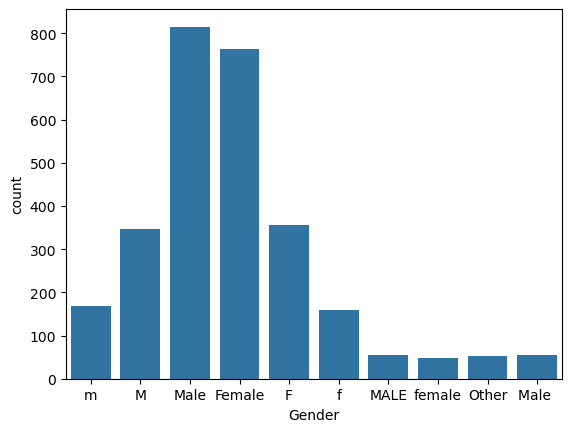

In [17]:
sns.countplot(x = df['Gender'])

#This is why data cleaning a be done first and them data visualization.

In [18]:
df['Gender'].unique()

array(['m', 'M', 'Male', nan, 'Female', 'F', 'f', 'MALE', 'female',
       'Other', 'Male '], dtype=object)

In [19]:
df['Gender']=df['Gender'].str.strip().str.lower()
df['Gender'].unique()

array(['m', 'male', nan, 'female', 'f', 'other'], dtype=object)

In [20]:
df['Gender'].replace({'m':'Male','male':'Male','female':'Female','f':'Female','other':'Other'},inplace=True)

C:\Users\mkrga\AppData\Local\Temp\ipykernel_16188\1359227077.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Gender'].replace({'m':'Male','male':'Male','female':'Female','f':'Female','other':'Other'},inplace=True)


In [21]:
df['Gender'].unique()

array(['Male', nan, 'Female', 'Other'], dtype=object)

<Axes: xlabel='Gender', ylabel='count'>

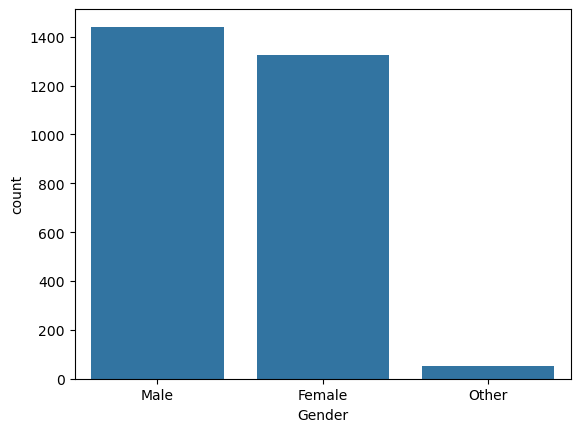

In [22]:
sns.countplot(x = df['Gender'])

In [23]:
df.head()

,OrderID,OrderDate,CustomerName,CustomerAge,Gender,CustomerCity,ProductCategory,ProductName,Quantity,UnitPrice,DiscountPercent,DeliveryDays,PaymentMethod,CustomerRating,ShippingCost,CouponCode,ReturnReason
0,ORD100674,2024-07-20,Diya Verma,34.0,Male,Delhi,Beauty & Personal Care,Lip Balm Pack,4.0,144.70,0.0,4.0,Net Banking,4.0,0.0,NaN,NaN
1,ORD102063,2024-10-17,Reyansh Sharma,31.0,Male,Kolkata,Footwear,Formal Leather Shoes,2.0,486.07,40.0,2.0,Debit Card,NaN,0.0,NEWUSER15,NaN
2,ORD100377,2024-11-11,Sara Deshmukh,51.0,Male,Pune,Apparel,Men Cotton T-Shirt,1.0,852.46,10.0,3.0,Credit Card,4.0,NaN,FEST20,NaN
3,ORD100802,2024-04-14,Riya Kapoor,49.0,NaN,Nagpur,Apparel,Men Cotton T-Shirt,1.0,1246.09,0.0,2.0,NaN,NaN,NaN,NEWUSER15,NaN
4,ORD101208,2023-09-17,Sneha Pillai,39.0,Male,Lucknow,Grocery,Green Tea Pack,1.0,379.31,25.0,4.0,Debit Card,NaN,80.0,FLAT100,NaN


In [24]:
df.describe()

,CustomerAge,Quantity,UnitPrice,DiscountPercent,DeliveryDays,CustomerRating,ShippingCost
count,2910.000000,3000.000000,2925.000000,3000.000000,3000.000000,2160.000000,1950.000000
mean,34.683849,2.854333,997.884354,12.955000,5.834000,3.840278,52.010256
std,12.086021,10.648830,1030.098789,12.790524,4.604944,1.165725,46.232729
min,0.000000,-5.000000,80.350000,-25.000000,-3.000000,1.000000,0.000000
25%,28.000000,1.000000,478.610000,5.000000,4.000000,3.000000,0.000000
50%,34.000000,2.000000,786.670000,10.000000,5.000000,4.000000,60.000000
75%,41.000000,3.000000,1328.540000,20.000000,8.000000,5.000000,80.000000
max,150.000000,200.000000,20819.867889,150.000000,60.000000,5.000000,150.000000


In [25]:
(df['DiscountPercent'] < 0).sum()

np.int64(10)

In [26]:
df['Quantity'].abs()

0       4.0
1       2.0
2       1.0
3       1.0
4       1.0
       ... 
3055    1.0
3056    4.0
3057    2.0
3058    1.0
3059    3.0
Name: Quantity, Length: 3000, dtype: float64

In [27]:
for i in ['Quantity','DiscountPercent','DeliveryDays']:
    negative_values = (df[i]<0).sum()
    df[i] = df[i].abs()
    print(f"{i} fixed {negative_values} values")


Quantity fixed 6 values
DiscountPercent fixed 10 values
DeliveryDays fixed 8 values


In [28]:
df.describe()

,CustomerAge,Quantity,UnitPrice,DiscountPercent,DeliveryDays,CustomerRating,ShippingCost
count,2910.000000,3000.000000,2925.000000,3000.000000,3000.000000,2160.000000,1950.000000
mean,34.683849,2.869000,997.884354,13.051667,5.842000,3.840278,52.010256
std,12.086021,10.644887,1030.098789,12.691836,4.594788,1.165725,46.232729
min,0.000000,0.000000,80.350000,0.000000,1.000000,1.000000,0.000000
25%,28.000000,1.000000,478.610000,5.000000,4.000000,3.000000,0.000000
50%,34.000000,2.000000,786.670000,10.000000,5.000000,4.000000,60.000000
75%,41.000000,3.000000,1328.540000,20.000000,8.000000,5.000000,80.000000
max,150.000000,200.000000,20819.867889,150.000000,60.000000,5.000000,150.000000


# Discount and Percentage

In [29]:
(df['DiscountPercent']>100).sum()

np.int64(5)

In [30]:
df[df['DiscountPercent']>100]   #Getting all rows where discount percentage is more than 100.

,OrderID,OrderDate,CustomerName,CustomerAge,Gender,CustomerCity,ProductCategory,ProductName,Quantity,UnitPrice,DiscountPercent,DeliveryDays,PaymentMethod,CustomerRating,ShippingCost,CouponCode,ReturnReason
114,ORD102430,2023-05-01,Sara Gupta,39.0,Male,Delhi,Beauty & Personal Care,Sunscreen SPF50,2.0,770.10,150.0,5.0,Credit Card,3.0,40.0,FLAT100,NaN
613,ORD100453,2023-01-23,Kabir Bhat,42.0,Male,Delhi,Footwear,Sandals,4.0,1422.12,120.0,5.0,NaN,5.0,40.0,NaN,NaN
656,ORD102470,2025-03-23,Pari Iyer,57.0,NaN,Hyderabad,Footwear,Formal Leather Shoes,5.0,1501.22,120.0,9.0,UPI,4.0,0.0,WELCOME50,NaN
1654,ORD102209,2023-05-07,Karan Pillai,46.0,Female,Pune,Beauty & Personal Care,Body Lotion,4.0,527.66,120.0,5.0,UPI,5.0,NaN,NaN,NaN
2845,ORD102476,2024-04-20,Priya Bhat,25.0,Male,Mumbai,Grocery,Basmati Rice 5kg,3.0,219.99,120.0,7.0,UPI,4.0,80.0,NaN,NaN


In [31]:
#clipping discount

In [32]:
df['DiscountPercent'] = df['DiscountPercent'].clip(upper = 100)

In [33]:
df.head()

,OrderID,OrderDate,CustomerName,CustomerAge,Gender,CustomerCity,ProductCategory,ProductName,Quantity,UnitPrice,DiscountPercent,DeliveryDays,PaymentMethod,CustomerRating,ShippingCost,CouponCode,ReturnReason
0,ORD100674,2024-07-20,Diya Verma,34.0,Male,Delhi,Beauty & Personal Care,Lip Balm Pack,4.0,144.70,0.0,4.0,Net Banking,4.0,0.0,NaN,NaN
1,ORD102063,2024-10-17,Reyansh Sharma,31.0,Male,Kolkata,Footwear,Formal Leather Shoes,2.0,486.07,40.0,2.0,Debit Card,NaN,0.0,NEWUSER15,NaN
2,ORD100377,2024-11-11,Sara Deshmukh,51.0,Male,Pune,Apparel,Men Cotton T-Shirt,1.0,852.46,10.0,3.0,Credit Card,4.0,NaN,FEST20,NaN
3,ORD100802,2024-04-14,Riya Kapoor,49.0,NaN,Nagpur,Apparel,Men Cotton T-Shirt,1.0,1246.09,0.0,2.0,NaN,NaN,NaN,NEWUSER15,NaN
4,ORD101208,2023-09-17,Sneha Pillai,39.0,Male,Lucknow,Grocery,Green Tea Pack,1.0,379.31,25.0,4.0,Debit Card,NaN,80.0,FLAT100,NaN


In [34]:
df.loc[[114,613,656,1645,2845]]

,OrderID,OrderDate,CustomerName,CustomerAge,Gender,CustomerCity,ProductCategory,ProductName,Quantity,UnitPrice,DiscountPercent,DeliveryDays,PaymentMethod,CustomerRating,ShippingCost,CouponCode,ReturnReason
114,ORD102430,2023-05-01,Sara Gupta,39.0,Male,Delhi,Beauty & Personal Care,Sunscreen SPF50,2.0,770.10,100.0,5.0,Credit Card,3.0,40.0,FLAT100,NaN
613,ORD100453,2023-01-23,Kabir Bhat,42.0,Male,Delhi,Footwear,Sandals,4.0,1422.12,100.0,5.0,NaN,5.0,40.0,NaN,NaN
656,ORD102470,2025-03-23,Pari Iyer,57.0,NaN,Hyderabad,Footwear,Formal Leather Shoes,5.0,1501.22,100.0,9.0,UPI,4.0,0.0,WELCOME50,NaN
1645,ORD100274,2024-01-16,Krishna Joshi,26.0,Female,Delhi,Electronics,Portable Speaker,1.0,2176.12,20.0,2.0,UPI,4.0,40.0,NaN,NaN
2845,ORD102476,2024-04-20,Priya Bhat,25.0,Male,Mumbai,Grocery,Basmati Rice 5kg,3.0,219.99,100.0,7.0,UPI,4.0,80.0,NaN,NaN


In [35]:
df.describe()

,CustomerAge,Quantity,UnitPrice,DiscountPercent,DeliveryDays,CustomerRating,ShippingCost
count,2910.000000,3000.000000,2925.000000,3000.000000,3000.000000,2160.000000,1950.000000
mean,34.683849,2.869000,997.884354,13.008333,5.842000,3.840278,52.010256
std,12.086021,10.644887,1030.098789,12.335950,4.594788,1.165725,46.232729
min,0.000000,0.000000,80.350000,0.000000,1.000000,1.000000,0.000000
25%,28.000000,1.000000,478.610000,5.000000,4.000000,3.000000,0.000000
50%,34.000000,2.000000,786.670000,10.000000,5.000000,4.000000,60.000000
75%,41.000000,3.000000,1328.540000,20.000000,8.000000,5.000000,80.000000
max,150.000000,200.000000,20819.867889,100.000000,60.000000,5.000000,150.000000


In [36]:
df.head()

,OrderID,OrderDate,CustomerName,CustomerAge,Gender,CustomerCity,ProductCategory,ProductName,Quantity,UnitPrice,DiscountPercent,DeliveryDays,PaymentMethod,CustomerRating,ShippingCost,CouponCode,ReturnReason
0,ORD100674,2024-07-20,Diya Verma,34.0,Male,Delhi,Beauty & Personal Care,Lip Balm Pack,4.0,144.70,0.0,4.0,Net Banking,4.0,0.0,NaN,NaN
1,ORD102063,2024-10-17,Reyansh Sharma,31.0,Male,Kolkata,Footwear,Formal Leather Shoes,2.0,486.07,40.0,2.0,Debit Card,NaN,0.0,NEWUSER15,NaN
2,ORD100377,2024-11-11,Sara Deshmukh,51.0,Male,Pune,Apparel,Men Cotton T-Shirt,1.0,852.46,10.0,3.0,Credit Card,4.0,NaN,FEST20,NaN
3,ORD100802,2024-04-14,Riya Kapoor,49.0,NaN,Nagpur,Apparel,Men Cotton T-Shirt,1.0,1246.09,0.0,2.0,NaN,NaN,NaN,NEWUSER15,NaN
4,ORD101208,2023-09-17,Sneha Pillai,39.0,Male,Lucknow,Grocery,Green Tea Pack,1.0,379.31,25.0,4.0,Debit Card,NaN,80.0,FLAT100,NaN


In [37]:
np.nan  #Return actual nan value of the table.

nan

In [38]:
df.CustomerAge

0       34.0
1       31.0
2       51.0
3       49.0
4       39.0
        ... 
3055    24.0
3056    48.0
3057    33.0
3058    24.0
3059    38.0
Name: CustomerAge, Length: 3000, dtype: float64

In [39]:
df[(df['CustomerAge'] < 16) | (df['CustomerAge'] > 85)]   #Get rows where age is invalid

,OrderID,OrderDate,CustomerName,CustomerAge,Gender,CustomerCity,ProductCategory,ProductName,Quantity,UnitPrice,DiscountPercent,DeliveryDays,PaymentMethod,CustomerRating,ShippingCost,CouponCode,ReturnReason
5,ORD102726,2023-05-05,Anika Pillai,15.0,Female,Pune,Electronics,LED Bulb Smart,2.0,2346.35,15.0,5.0,UPI,5.0,80.0,NaN,Size Issue
12,ORD100727,2023-01-10,Ishita Joshi,15.0,Male,Ahmedabad,Grocery,Whole Wheat Atta 5kg,4.0,405.44,0.0,8.0,NaN,4.0,NaN,NaN,NaN
46,ORD101236,2023-11-03,Sneha Joshi,15.0,Male,Ahmedabad,Grocery,Cooking Oil 1L,1.0,430.97,25.0,3.0,Net Banking,4.0,150.0,NaN,NaN
63,ORD101545,2024-06-21,Aadhya Menon,15.0,Male,Chennai,Footwear,Formal Leather Shoes,1.0,1211.00,5.0,9.0,Credit Card,NaN,0.0,NaN,NaN
81,ORD102141,2025-03-08,Priya Chopra,15.0,Male,Mumbai,Grocery,Honey 500g,1.0,613.70,25.0,6.0,UPI,2.0,40.0,FLAT100,Late Delivery
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2646,ORD101660,2024-07-18,Riya Reddy,120.0,Male,Kolkata,Beauty & Personal Care,Perfume 50ml,2.0,560.99,0.0,2.0,UPI,3.0,0.0,NaN,Wrong Item Delivered
2702,ORD101829,2024-01-02,Pari Mehta,15.0,Female,Chennai,Electronics,Wireless Mouse,1.0,1911.93,10.0,3.0,UPI,4.0,NaN,NaN,NaN
2837,ORD102569,2025-04-24,Amit Shah,15.0,Female,Ahmedabad,Apparel,Woolen Sweater,2.0,1009.54,10.0,6.0,Debit Card,NaN,100.0,NaN,NaN
2915,ORD101356,2023-12-15,Kabir Joshi,95.0,Female,Kolkata,Electronics,Smartphone Cover,3.0,1769.62,15.0,3.0,UPI,5.0,NaN,NaN,NaN


In [40]:
df.loc[(df['CustomerAge'] < 16) | (df['CustomerAge'] > 85),'CustomerAge'] = np.nan
#replce all invalid age with nan.

In [41]:
df[(df['CustomerAge'] < 16) | (df['CustomerAge'] > 85)]

,OrderID,OrderDate,CustomerName,CustomerAge,Gender,CustomerCity,ProductCategory,ProductName,Quantity,UnitPrice,DiscountPercent,DeliveryDays,PaymentMethod,CustomerRating,ShippingCost,CouponCode,ReturnReason


In [42]:
df.describe()

,CustomerAge,Quantity,UnitPrice,DiscountPercent,DeliveryDays,CustomerRating,ShippingCost
count,2798.000000,3000.000000,2925.000000,3000.000000,3000.000000,2160.000000,1950.000000
mean,34.652252,2.869000,997.884354,13.008333,5.842000,3.840278,52.010256
std,9.281069,10.644887,1030.098789,12.335950,4.594788,1.165725,46.232729
min,16.000000,0.000000,80.350000,0.000000,1.000000,1.000000,0.000000
25%,28.000000,1.000000,478.610000,5.000000,4.000000,3.000000,0.000000
50%,34.000000,2.000000,786.670000,10.000000,5.000000,4.000000,60.000000
75%,41.000000,3.000000,1328.540000,20.000000,8.000000,5.000000,80.000000
max,70.000000,200.000000,20819.867889,100.000000,60.000000,5.000000,150.000000


# Dealing With Missing Value
- if the missing value in the column in between 0 to 5% -> Drop rows with NA
-  if the missing value in the column in between 5 to 50% -> Replace NA [numerical column(mean,median)],[text column(mode)]
-  if the column contain more than 50% of NA value -> Delete column with NA

In [43]:
df['CustomerAge'].mean()

np.float64(34.652251608291635)

In [44]:
df['CustomerAge'].median()

34.0

In [45]:
df['Gender'].mode()

0    Male
Name: Gender, dtype: object

In [46]:
df['Gender'].value_counts()

Gender
Male      1441
Female    1326
Other       53
Name: count, dtype: int64

In [47]:
#Delete null value from all column
df.isnull().sum()

OrderID               0
OrderDate             0
CustomerName          0
CustomerAge         202
Gender              180
CustomerCity        240
ProductCategory       0
ProductName           0
Quantity              0
UnitPrice            75
DiscountPercent       0
DeliveryDays          0
PaymentMethod       540
CustomerRating      840
ShippingCost       1050
CouponCode         2160
ReturnReason       2640
dtype: int64

In [48]:
(df.isnull().sum()/len(df))*100

OrderID             0.000000
OrderDate           0.000000
CustomerName        0.000000
CustomerAge         6.733333
Gender              6.000000
CustomerCity        8.000000
ProductCategory     0.000000
ProductName         0.000000
Quantity            0.000000
UnitPrice           2.500000
DiscountPercent     0.000000
DeliveryDays        0.000000
PaymentMethod      18.000000
CustomerRating     28.000000
ShippingCost       35.000000
CouponCode         72.000000
ReturnReason       88.000000
dtype: float64

In [49]:
df[df['UnitPrice'].isna()]  #Show NA values in UnitPrice col.

,OrderID,OrderDate,CustomerName,CustomerAge,Gender,CustomerCity,ProductCategory,ProductName,Quantity,UnitPrice,DiscountPercent,DeliveryDays,PaymentMethod,CustomerRating,ShippingCost,CouponCode,ReturnReason
117,ORD102396,2025-05-12,Amit Patel,56.0,Male,Indore,Home & Kitchen,Cotton Bedsheet Set,1.0,NaN,5.0,6.0,NaN,5.0,0.0,NaN,NaN
119,ORD100419,2024-04-06,Arjun Iyer,21.0,Female,Kolkata,Home & Kitchen,Storage Container Set,2.0,NaN,0.0,7.0,Debit Card,NaN,60.0,SAVE10,NaN
175,ORD102498,2023-01-30,Vihaan Kulkarni,46.0,Male,Delhi,Grocery,Instant Noodles Pack,2.0,NaN,10.0,8.0,UPI,5.0,100.0,NaN,NaN
216,ORD102528,2023-03-20,Arjun Deshmukh,NaN,NaN,Lucknow,Apparel,Men Cotton T-Shirt,75.0,NaN,30.0,3.0,Net Banking,4.0,NaN,NaN,NaN
258,ORD101436,2023-10-21,Sara Reddy,NaN,Female,NaN,Beauty & Personal Care,Hair Oil 200ml,1.0,NaN,30.0,2.0,Credit Card,4.0,0.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3011,ORD102327,2023-06-03,Aditya Bhat,25.0,Male,Kochi,Home & Kitchen,Steel Water Bottle,1.0,NaN,0.0,7.0,UPI,5.0,NaN,NaN,NaN
3017,ORD101951,2024-07-08,Arjun Agarwal,45.0,Male,Bengaluru,Electronics,Smartphone Cover,1.0,NaN,20.0,9.0,UPI,NaN,40.0,NaN,NaN
3019,ORD101728,2023-01-16,Aarav Shah,41.0,Male,Bengaluru,Grocery,Honey 500g,3.0,NaN,0.0,3.0,UPI,4.0,100.0,NaN,NaN
3047,ORD102602,2024-12-12,Nikhil Mehta,33.0,Male,NaN,Electronics,Power Bank 10000mAh,2.0,NaN,30.0,4.0,UPI,NaN,60.0,NaN,NaN


In [50]:
df.shape

(3000, 17)

In [51]:
df.dropna(subset=['UnitPrice'],inplace=True)  #Deleting all na value only for UnitPrice col.

In [52]:
df.isna().sum()

OrderID               0
OrderDate             0
CustomerName          0
CustomerAge         196
Gender              173
CustomerCity        231
ProductCategory       0
ProductName           0
Quantity              0
UnitPrice             0
DiscountPercent       0
DeliveryDays          0
PaymentMethod       532
CustomerRating      821
ShippingCost       1026
CouponCode         2104
ReturnReason       2570
dtype: int64

# Replace Value 

In [53]:
#CustomerAge,Gender,Customer City,PaymentMethod,CustomerRatting,ShippimgCost

In [54]:
df.dtypes

OrderID             object
OrderDate           object
CustomerName        object
CustomerAge        float64
Gender              object
CustomerCity        object
ProductCategory     object
ProductName         object
Quantity           float64
UnitPrice          float64
DiscountPercent    float64
DeliveryDays       float64
PaymentMethod       object
CustomerRating     float64
ShippingCost       float64
CouponCode          object
ReturnReason        object
dtype: object

In [55]:
df['CustomerAge'].median()

34.0

In [56]:
df['CustomerAge'].fillna(34,inplace=True)

C:\Users\mkrga\AppData\Local\Temp\ipykernel_16188\50114958.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['CustomerAge'].fillna(34,inplace=True)


In [57]:
df.isna().sum()

OrderID               0
OrderDate             0
CustomerName          0
CustomerAge           0
Gender              173
CustomerCity        231
ProductCategory       0
ProductName           0
Quantity              0
UnitPrice             0
DiscountPercent       0
DeliveryDays          0
PaymentMethod       532
CustomerRating      821
ShippingCost       1026
CouponCode         2104
ReturnReason       2570
dtype: int64

In [58]:
df.shape

(2925, 17)

In [59]:
import warnings
warnings.filterwarnings('ignore')

In [60]:
#CustomerAge,Gender,CustomerCity,PaymentMethod,CustomerRatting,ShippimgCost
print(df['Gender'].mode())
print(df['CustomerCity'].mode())
print(df['PaymentMethod'].mode())
print(df['CustomerRating'].median())
print(df['ShippingCost'].median())

0    Male
Name: Gender, dtype: object
0    Lucknow
Name: CustomerCity, dtype: object
0    UPI
Name: PaymentMethod, dtype: object
4.0
60.0


In [61]:
df.fillna({'Gender':'Male','CustomerCity':'Lucknow','PaymentMethod':'UPI','CustomerRating':4,'ShippingCost':60},inplace=True)

In [62]:
df.isna().sum()

OrderID               0
OrderDate             0
CustomerName          0
CustomerAge           0
Gender                0
CustomerCity          0
ProductCategory       0
ProductName           0
Quantity              0
UnitPrice             0
DiscountPercent       0
DeliveryDays          0
PaymentMethod         0
CustomerRating        0
ShippingCost          0
CouponCode         2104
ReturnReason       2570
dtype: int64

# Delete Column

In [63]:
df['CouponCode'].value_counts()

CouponCode
SAVE10       179
FLAT100      168
FEST20       167
WELCOME50    156
NEWUSER15    151
Name: count, dtype: int64

In [64]:
df['ReturnReason'].value_counts()

ReturnReason
Changed Mind               67
Late Delivery              62
Wrong Item Delivered       62
Defective Product          61
Size Issue                 53
Quality Not as Expected    50
Name: count, dtype: int64

In [65]:
df.drop(columns=['CouponCode','ReturnReason'])
#deleted col temp as they are imp as per the domain.

,OrderID,OrderDate,CustomerName,CustomerAge,Gender,CustomerCity,ProductCategory,ProductName,Quantity,UnitPrice,DiscountPercent,DeliveryDays,PaymentMethod,CustomerRating,ShippingCost
0,ORD100674,2024-07-20,Diya Verma,34.0,Male,Delhi,Beauty & Personal Care,Lip Balm Pack,4.0,144.70,0.0,4.0,Net Banking,4.0,0.0
1,ORD102063,2024-10-17,Reyansh Sharma,31.0,Male,Kolkata,Footwear,Formal Leather Shoes,2.0,486.07,40.0,2.0,Debit Card,4.0,0.0
2,ORD100377,2024-11-11,Sara Deshmukh,51.0,Male,Pune,Apparel,Men Cotton T-Shirt,1.0,852.46,10.0,3.0,Credit Card,4.0,60.0
3,ORD100802,2024-04-14,Riya Kapoor,49.0,Male,Nagpur,Apparel,Men Cotton T-Shirt,1.0,1246.09,0.0,2.0,UPI,4.0,60.0
4,ORD101208,2023-09-17,Sneha Pillai,39.0,Male,Lucknow,Grocery,Green Tea Pack,1.0,379.31,25.0,4.0,Debit Card,4.0,80.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3054,ORD100211,2024-10-15,Amit Menon,49.0,Female,Kochi,Home & Kitchen,Storage Container Set,3.0,655.70,0.0,5.0,UPI,5.0,60.0
3055,ORD101603,2023-10-16,Reyansh Deshmukh,24.0,Male,Delhi,Apparel,Sports Track Pant,1.0,468.47,20.0,5.0,Credit Card,4.0,60.0
3056,ORD102550,2024-11-13,Anika Kulkarni,48.0,Female,Jaipur,Home & Kitchen,Non-Stick Pan,4.0,1360.28,5.0,5.0,Cash on Delivery,5.0,60.0
3057,ORD100537,2023-04-16,Myra Bhat,33.0,Female,Chandigarh,Beauty & Personal Care,Hair Oil 200ml,2.0,695.55,50.0,8.0,UPI,4.0,80.0


# Create new col


In [66]:
df.head()

,OrderID,OrderDate,CustomerName,CustomerAge,Gender,CustomerCity,ProductCategory,ProductName,Quantity,UnitPrice,DiscountPercent,DeliveryDays,PaymentMethod,CustomerRating,ShippingCost,CouponCode,ReturnReason
0,ORD100674,2024-07-20,Diya Verma,34.0,Male,Delhi,Beauty & Personal Care,Lip Balm Pack,4.0,144.70,0.0,4.0,Net Banking,4.0,0.0,NaN,NaN
1,ORD102063,2024-10-17,Reyansh Sharma,31.0,Male,Kolkata,Footwear,Formal Leather Shoes,2.0,486.07,40.0,2.0,Debit Card,4.0,0.0,NEWUSER15,NaN
2,ORD100377,2024-11-11,Sara Deshmukh,51.0,Male,Pune,Apparel,Men Cotton T-Shirt,1.0,852.46,10.0,3.0,Credit Card,4.0,60.0,FEST20,NaN
3,ORD100802,2024-04-14,Riya Kapoor,49.0,Male,Nagpur,Apparel,Men Cotton T-Shirt,1.0,1246.09,0.0,2.0,UPI,4.0,60.0,NEWUSER15,NaN
4,ORD101208,2023-09-17,Sneha Pillai,39.0,Male,Lucknow,Grocery,Green Tea Pack,1.0,379.31,25.0,4.0,Debit Card,4.0,80.0,FLAT100,NaN


In [67]:
df['Sales'] = (df['Quantity']*df['UnitPrice']*(1 - df['DiscountPercent']/100)) + df['ShippingCost']

In [68]:
df.head()

,OrderID,OrderDate,CustomerName,CustomerAge,Gender,CustomerCity,ProductCategory,ProductName,Quantity,UnitPrice,DiscountPercent,DeliveryDays,PaymentMethod,CustomerRating,ShippingCost,CouponCode,ReturnReason,Sales
0,ORD100674,2024-07-20,Diya Verma,34.0,Male,Delhi,Beauty & Personal Care,Lip Balm Pack,4.0,144.70,0.0,4.0,Net Banking,4.0,0.0,NaN,NaN,578.8000
1,ORD102063,2024-10-17,Reyansh Sharma,31.0,Male,Kolkata,Footwear,Formal Leather Shoes,2.0,486.07,40.0,2.0,Debit Card,4.0,0.0,NEWUSER15,NaN,583.2840
2,ORD100377,2024-11-11,Sara Deshmukh,51.0,Male,Pune,Apparel,Men Cotton T-Shirt,1.0,852.46,10.0,3.0,Credit Card,4.0,60.0,FEST20,NaN,827.2140
3,ORD100802,2024-04-14,Riya Kapoor,49.0,Male,Nagpur,Apparel,Men Cotton T-Shirt,1.0,1246.09,0.0,2.0,UPI,4.0,60.0,NEWUSER15,NaN,1306.0900
4,ORD101208,2023-09-17,Sneha Pillai,39.0,Male,Lucknow,Grocery,Green Tea Pack,1.0,379.31,25.0,4.0,Debit Card,4.0,80.0,FLAT100,NaN,364.4825


# Date Column

In [69]:
 df['OrderDate'] = pd.to_datetime(df['OrderDate'])

In [70]:
df['Year'] = df['OrderDate'].dt.year
df['Month'] = df['OrderDate'].dt.month_name()
df['Day'] = df['OrderDate'].dt.day_name()
df['Quarter'] = df['OrderDate'].dt.quarter

In [71]:
df.head()

,OrderID,OrderDate,CustomerName,CustomerAge,Gender,CustomerCity,ProductCategory,ProductName,Quantity,UnitPrice,...,PaymentMethod,CustomerRating,ShippingCost,CouponCode,ReturnReason,Sales,Year,Month,Day,Quarter
0,ORD100674,2024-07-20,Diya Verma,34.0,Male,Delhi,Beauty & Personal Care,Lip Balm Pack,4.0,144.70,...,Net Banking,4.0,0.0,NaN,NaN,578.8000,2024,July,Saturday,3
1,ORD102063,2024-10-17,Reyansh Sharma,31.0,Male,Kolkata,Footwear,Formal Leather Shoes,2.0,486.07,...,Debit Card,4.0,0.0,NEWUSER15,NaN,583.2840,2024,October,Thursday,4
2,ORD100377,2024-11-11,Sara Deshmukh,51.0,Male,Pune,Apparel,Men Cotton T-Shirt,1.0,852.46,...,Credit Card,4.0,60.0,FEST20,NaN,827.2140,2024,November,Monday,4
3,ORD100802,2024-04-14,Riya Kapoor,49.0,Male,Nagpur,Apparel,Men Cotton T-Shirt,1.0,1246.09,...,UPI,4.0,60.0,NEWUSER15,NaN,1306.0900,2024,April,Sunday,2
4,ORD101208,2023-09-17,Sneha Pillai,39.0,Male,Lucknow,Grocery,Green Tea Pack,1.0,379.31,...,Debit Card,4.0,80.0,FLAT100,NaN,364.4825,2023,September,Sunday,3


In [72]:
df['Year'].value_counts()

Year
2023    1260
2024    1236
2025     429
Name: count, dtype: int64

In [73]:
df.groupby('Year')['Month'].value_counts()

Year  Month    
2023  October      182
      December     171
      November     158
      January      154
      May          103
      April         79
      March         75
      September     73
      August        72
      June          71
      February      69
      July          53
2024  December     182
      January      164
      October      156
      November     153
      April         84
      February      82
      August        78
      March         73
      May           70
      July          67
      June          67
      September     60
2025  May           85
      February      80
      June          77
      April         72
      January       62
      March         53
Name: count, dtype: int64

In [74]:
df[df['Year'] == 2025]['Month'].unique()

array(['May', 'February', 'January', 'June', 'March', 'April'],
      dtype=object)

# Univariate Analysis

In [75]:
df.head(3)

,OrderID,OrderDate,CustomerName,CustomerAge,Gender,CustomerCity,ProductCategory,ProductName,Quantity,UnitPrice,...,PaymentMethod,CustomerRating,ShippingCost,CouponCode,ReturnReason,Sales,Year,Month,Day,Quarter
0,ORD100674,2024-07-20,Diya Verma,34.0,Male,Delhi,Beauty & Personal Care,Lip Balm Pack,4.0,144.70,...,Net Banking,4.0,0.0,NaN,NaN,578.800,2024,July,Saturday,3
1,ORD102063,2024-10-17,Reyansh Sharma,31.0,Male,Kolkata,Footwear,Formal Leather Shoes,2.0,486.07,...,Debit Card,4.0,0.0,NEWUSER15,NaN,583.284,2024,October,Thursday,4
2,ORD100377,2024-11-11,Sara Deshmukh,51.0,Male,Pune,Apparel,Men Cotton T-Shirt,1.0,852.46,...,Credit Card,4.0,60.0,FEST20,NaN,827.214,2024,November,Monday,4


In [76]:
text_col = list(df.select_dtypes(object).columns)
type(text_col)

list

In [77]:
text_col

['OrderID',
 'CustomerName',
 'Gender',
 'CustomerCity',
 'ProductCategory',
 'ProductName',
 'PaymentMethod',
 'CouponCode',
 'ReturnReason',
 'Month',
 'Day']

In [78]:
text_col.pop(0)
text_col.pop(0)

'CustomerName'

In [79]:
df.columns

Index(['OrderID', 'OrderDate', 'CustomerName', 'CustomerAge', 'Gender',
       'CustomerCity', 'ProductCategory', 'ProductName', 'Quantity',
       'UnitPrice', 'DiscountPercent', 'DeliveryDays', 'PaymentMethod',
       'CustomerRating', 'ShippingCost', 'CouponCode', 'ReturnReason', 'Sales',
       'Year', 'Month', 'Day', 'Quarter'],
      dtype='object')

In [80]:
text_col.extend(['Quantity','CustomerRating','Quarter'])
text_col

['Gender',
 'CustomerCity',
 'ProductCategory',
 'ProductName',
 'PaymentMethod',
 'CouponCode',
 'ReturnReason',
 'Month',
 'Day',
 'Quantity',
 'CustomerRating',
 'Quarter']

In [81]:
sns.set_theme(style = 'darkgrid',palette = 'viridis')

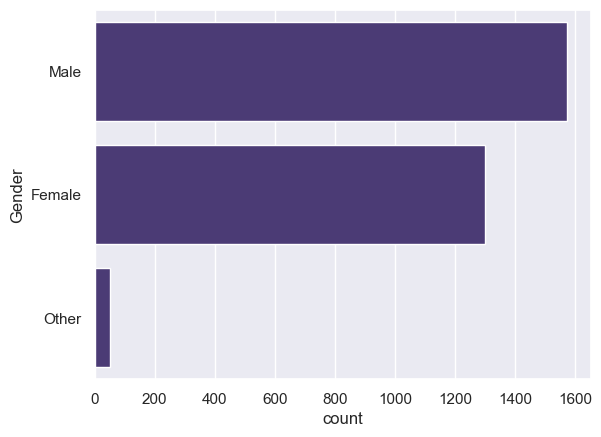

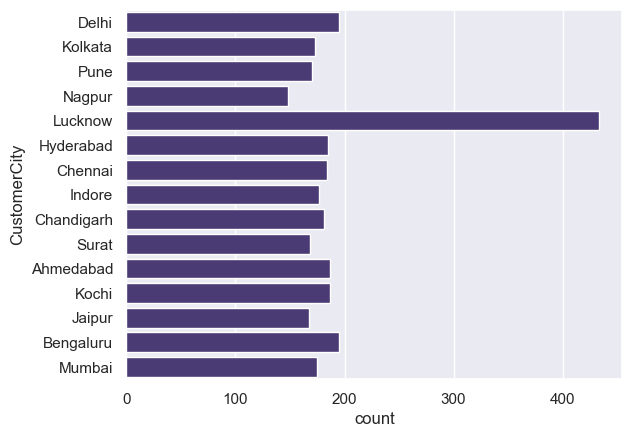

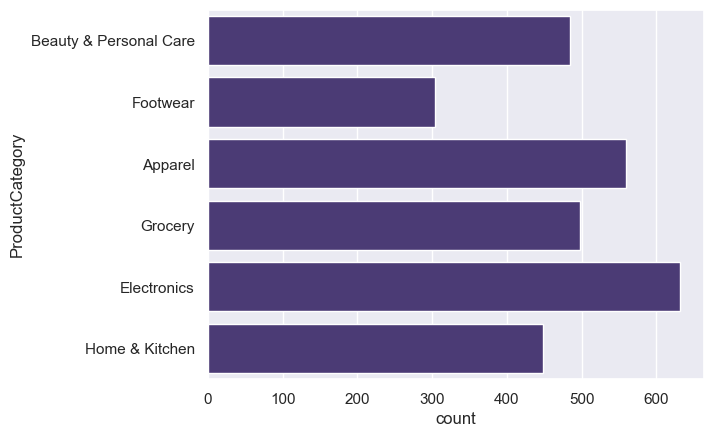

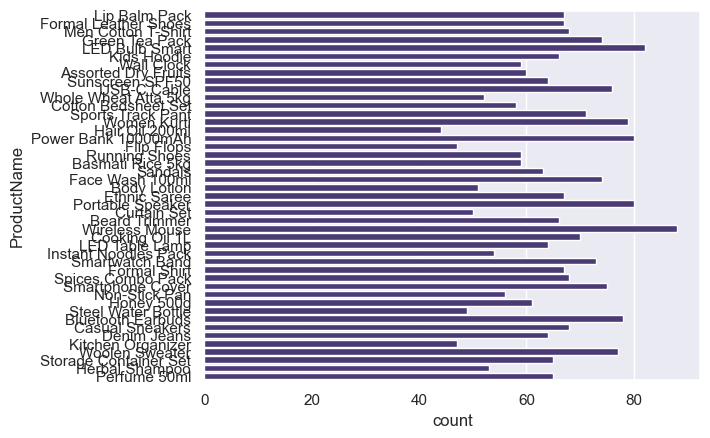

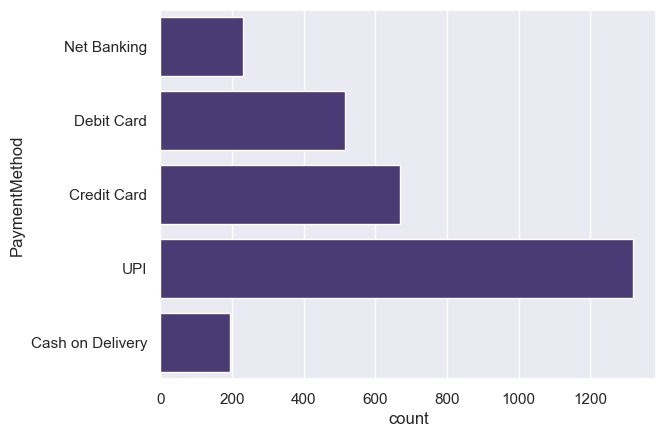

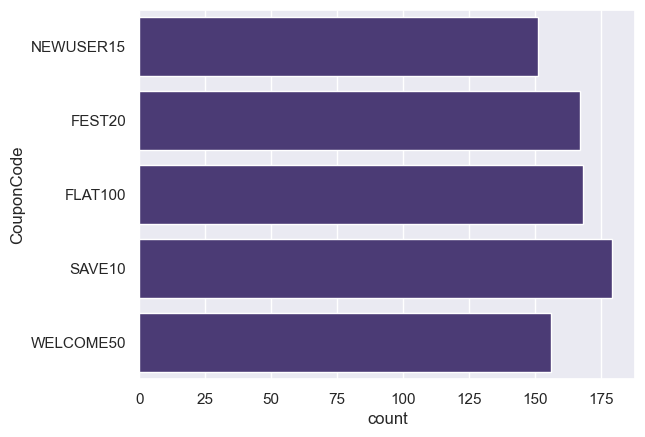

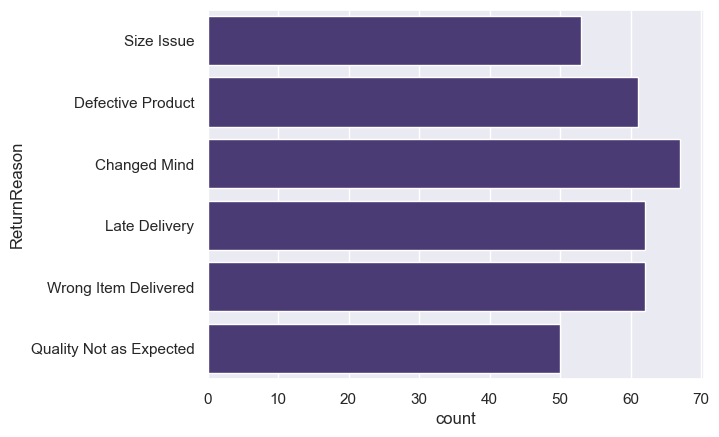

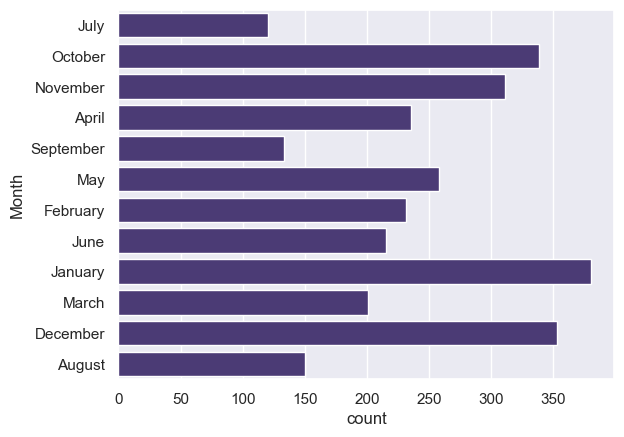

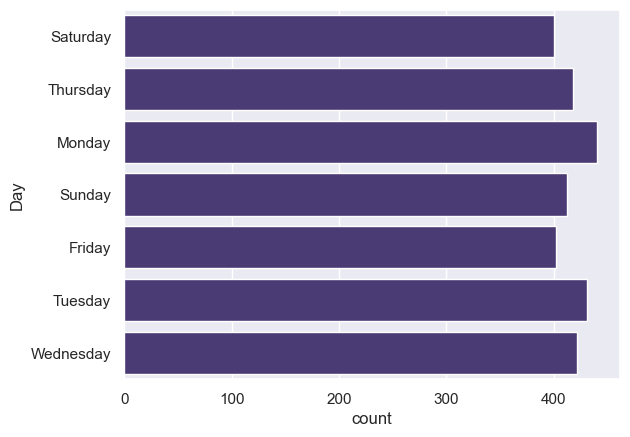

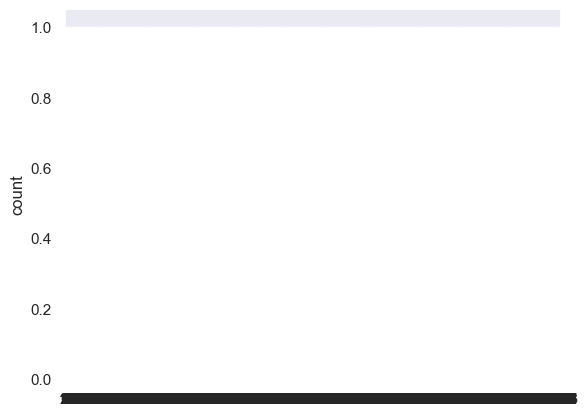

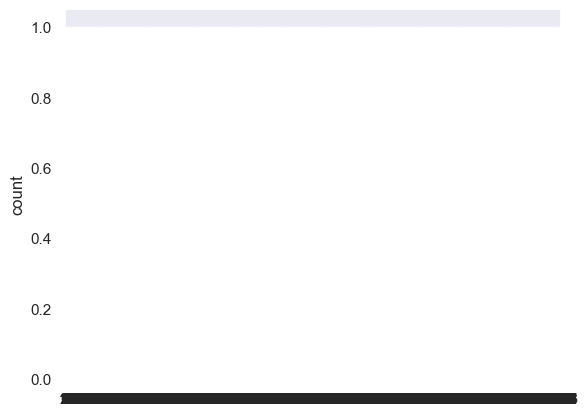

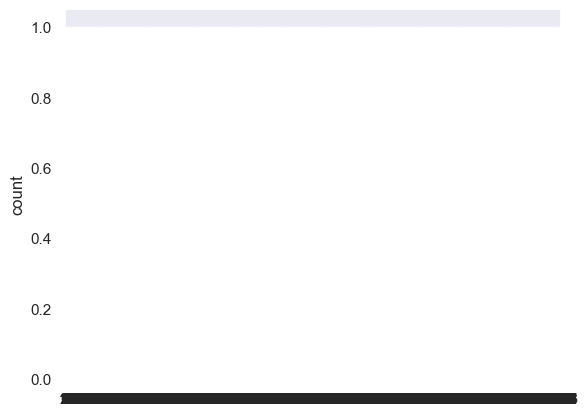

In [82]:
for i in text_col:
    sns.countplot(df[i])
    plt.show()

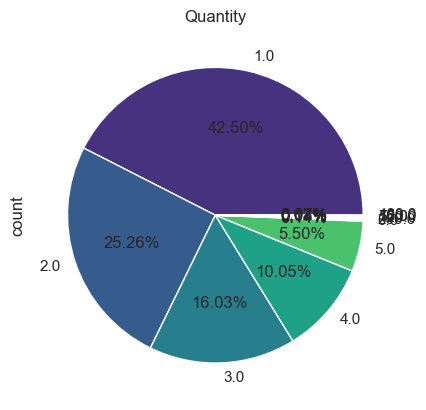

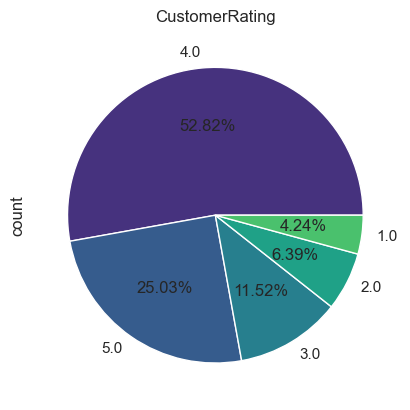

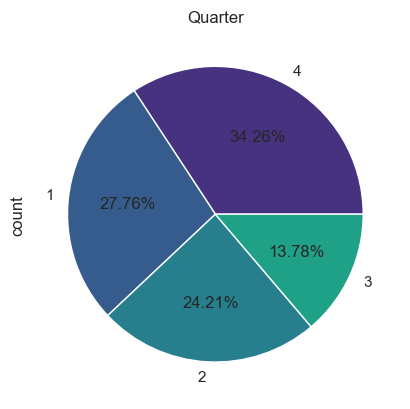

In [83]:
for i in ['Quantity','CustomerRating','Quarter']:
    df[i].value_counts().plot(kind = 'pie',autopct = '%0.2f%%')
    plt.title(i)
    plt.show()

In [84]:
df.head(3)

,OrderID,OrderDate,CustomerName,CustomerAge,Gender,CustomerCity,ProductCategory,ProductName,Quantity,UnitPrice,...,PaymentMethod,CustomerRating,ShippingCost,CouponCode,ReturnReason,Sales,Year,Month,Day,Quarter
0,ORD100674,2024-07-20,Diya Verma,34.0,Male,Delhi,Beauty & Personal Care,Lip Balm Pack,4.0,144.70,...,Net Banking,4.0,0.0,NaN,NaN,578.800,2024,July,Saturday,3
1,ORD102063,2024-10-17,Reyansh Sharma,31.0,Male,Kolkata,Footwear,Formal Leather Shoes,2.0,486.07,...,Debit Card,4.0,0.0,NEWUSER15,NaN,583.284,2024,October,Thursday,4
2,ORD100377,2024-11-11,Sara Deshmukh,51.0,Male,Pune,Apparel,Men Cotton T-Shirt,1.0,852.46,...,Credit Card,4.0,60.0,FEST20,NaN,827.214,2024,November,Monday,4


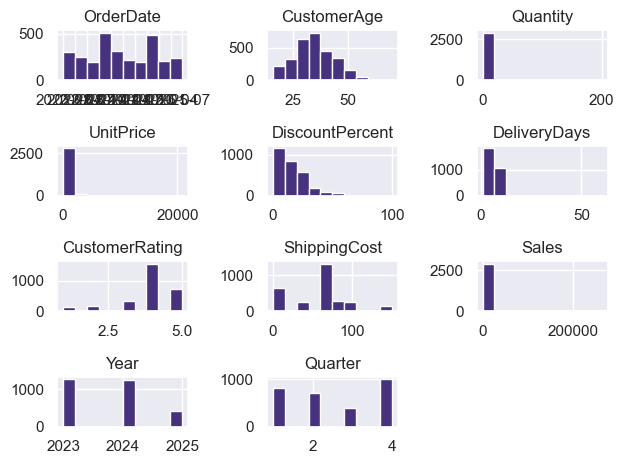

In [85]:
df.hist()
plt.tight_layout()

<Axes: >

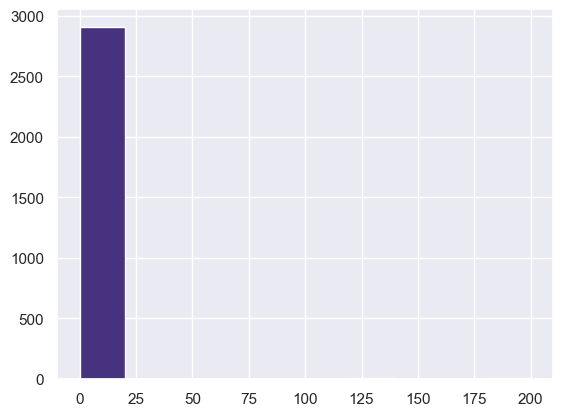

In [86]:
df['Quantity'].hist()

In [87]:
df.describe()

,OrderDate,CustomerAge,Quantity,UnitPrice,DiscountPercent,DeliveryDays,CustomerRating,ShippingCost,Sales,Year,Quarter
count,2925,2925.000000,2925.000000,2925.000000,2925.000000,2925.000000,2925.00000,2925.000000,2925.000000,2925.000000,2925.000000
mean,2024-03-20 20:16:59.076922880,34.609573,2.748376,997.884354,12.994872,5.837265,3.88000,54.902564,2380.787576,2023.715897,2.545299
min,2023-01-01 00:00:00,16.000000,0.000000,80.350000,0.000000,1.000000,1.00000,0.000000,0.000000,2023.000000,1.000000
25%,2023-09-22 00:00:00,29.000000,1.000000,478.610000,5.000000,4.000000,4.00000,40.000000,661.848000,2023.000000,1.000000
50%,2024-02-14 00:00:00,34.000000,2.000000,786.670000,10.000000,5.000000,4.00000,60.000000,1253.740000,2024.000000,2.000000
75%,2024-11-06 00:00:00,40.000000,3.000000,1328.540000,20.000000,8.000000,5.00000,60.000000,2338.550000,2024.000000,4.000000
max,2025-06-29 00:00:00,70.000000,200.000000,20819.867889,100.000000,60.000000,5.00000,150.000000,261862.125000,2025.000000,4.000000
std,NaN,8.952300,9.853663,1030.098789,12.356771,4.552346,0.99432,37.602106,8937.941312,0.704905,1.220163


# Bivariate Analysis

In [88]:
df.head(5)

,OrderID,OrderDate,CustomerName,CustomerAge,Gender,CustomerCity,ProductCategory,ProductName,Quantity,UnitPrice,...,PaymentMethod,CustomerRating,ShippingCost,CouponCode,ReturnReason,Sales,Year,Month,Day,Quarter
0,ORD100674,2024-07-20,Diya Verma,34.0,Male,Delhi,Beauty & Personal Care,Lip Balm Pack,4.0,144.70,...,Net Banking,4.0,0.0,NaN,NaN,578.8000,2024,July,Saturday,3
1,ORD102063,2024-10-17,Reyansh Sharma,31.0,Male,Kolkata,Footwear,Formal Leather Shoes,2.0,486.07,...,Debit Card,4.0,0.0,NEWUSER15,NaN,583.2840,2024,October,Thursday,4
2,ORD100377,2024-11-11,Sara Deshmukh,51.0,Male,Pune,Apparel,Men Cotton T-Shirt,1.0,852.46,...,Credit Card,4.0,60.0,FEST20,NaN,827.2140,2024,November,Monday,4
3,ORD100802,2024-04-14,Riya Kapoor,49.0,Male,Nagpur,Apparel,Men Cotton T-Shirt,1.0,1246.09,...,UPI,4.0,60.0,NEWUSER15,NaN,1306.0900,2024,April,Sunday,2
4,ORD101208,2023-09-17,Sneha Pillai,39.0,Male,Lucknow,Grocery,Green Tea Pack,1.0,379.31,...,Debit Card,4.0,80.0,FLAT100,NaN,364.4825,2023,September,Sunday,3


In [89]:
df.columns

Index(['OrderID', 'OrderDate', 'CustomerName', 'CustomerAge', 'Gender',
       'CustomerCity', 'ProductCategory', 'ProductName', 'Quantity',
       'UnitPrice', 'DiscountPercent', 'DeliveryDays', 'PaymentMethod',
       'CustomerRating', 'ShippingCost', 'CouponCode', 'ReturnReason', 'Sales',
       'Year', 'Month', 'Day', 'Quarter'],
      dtype='object')

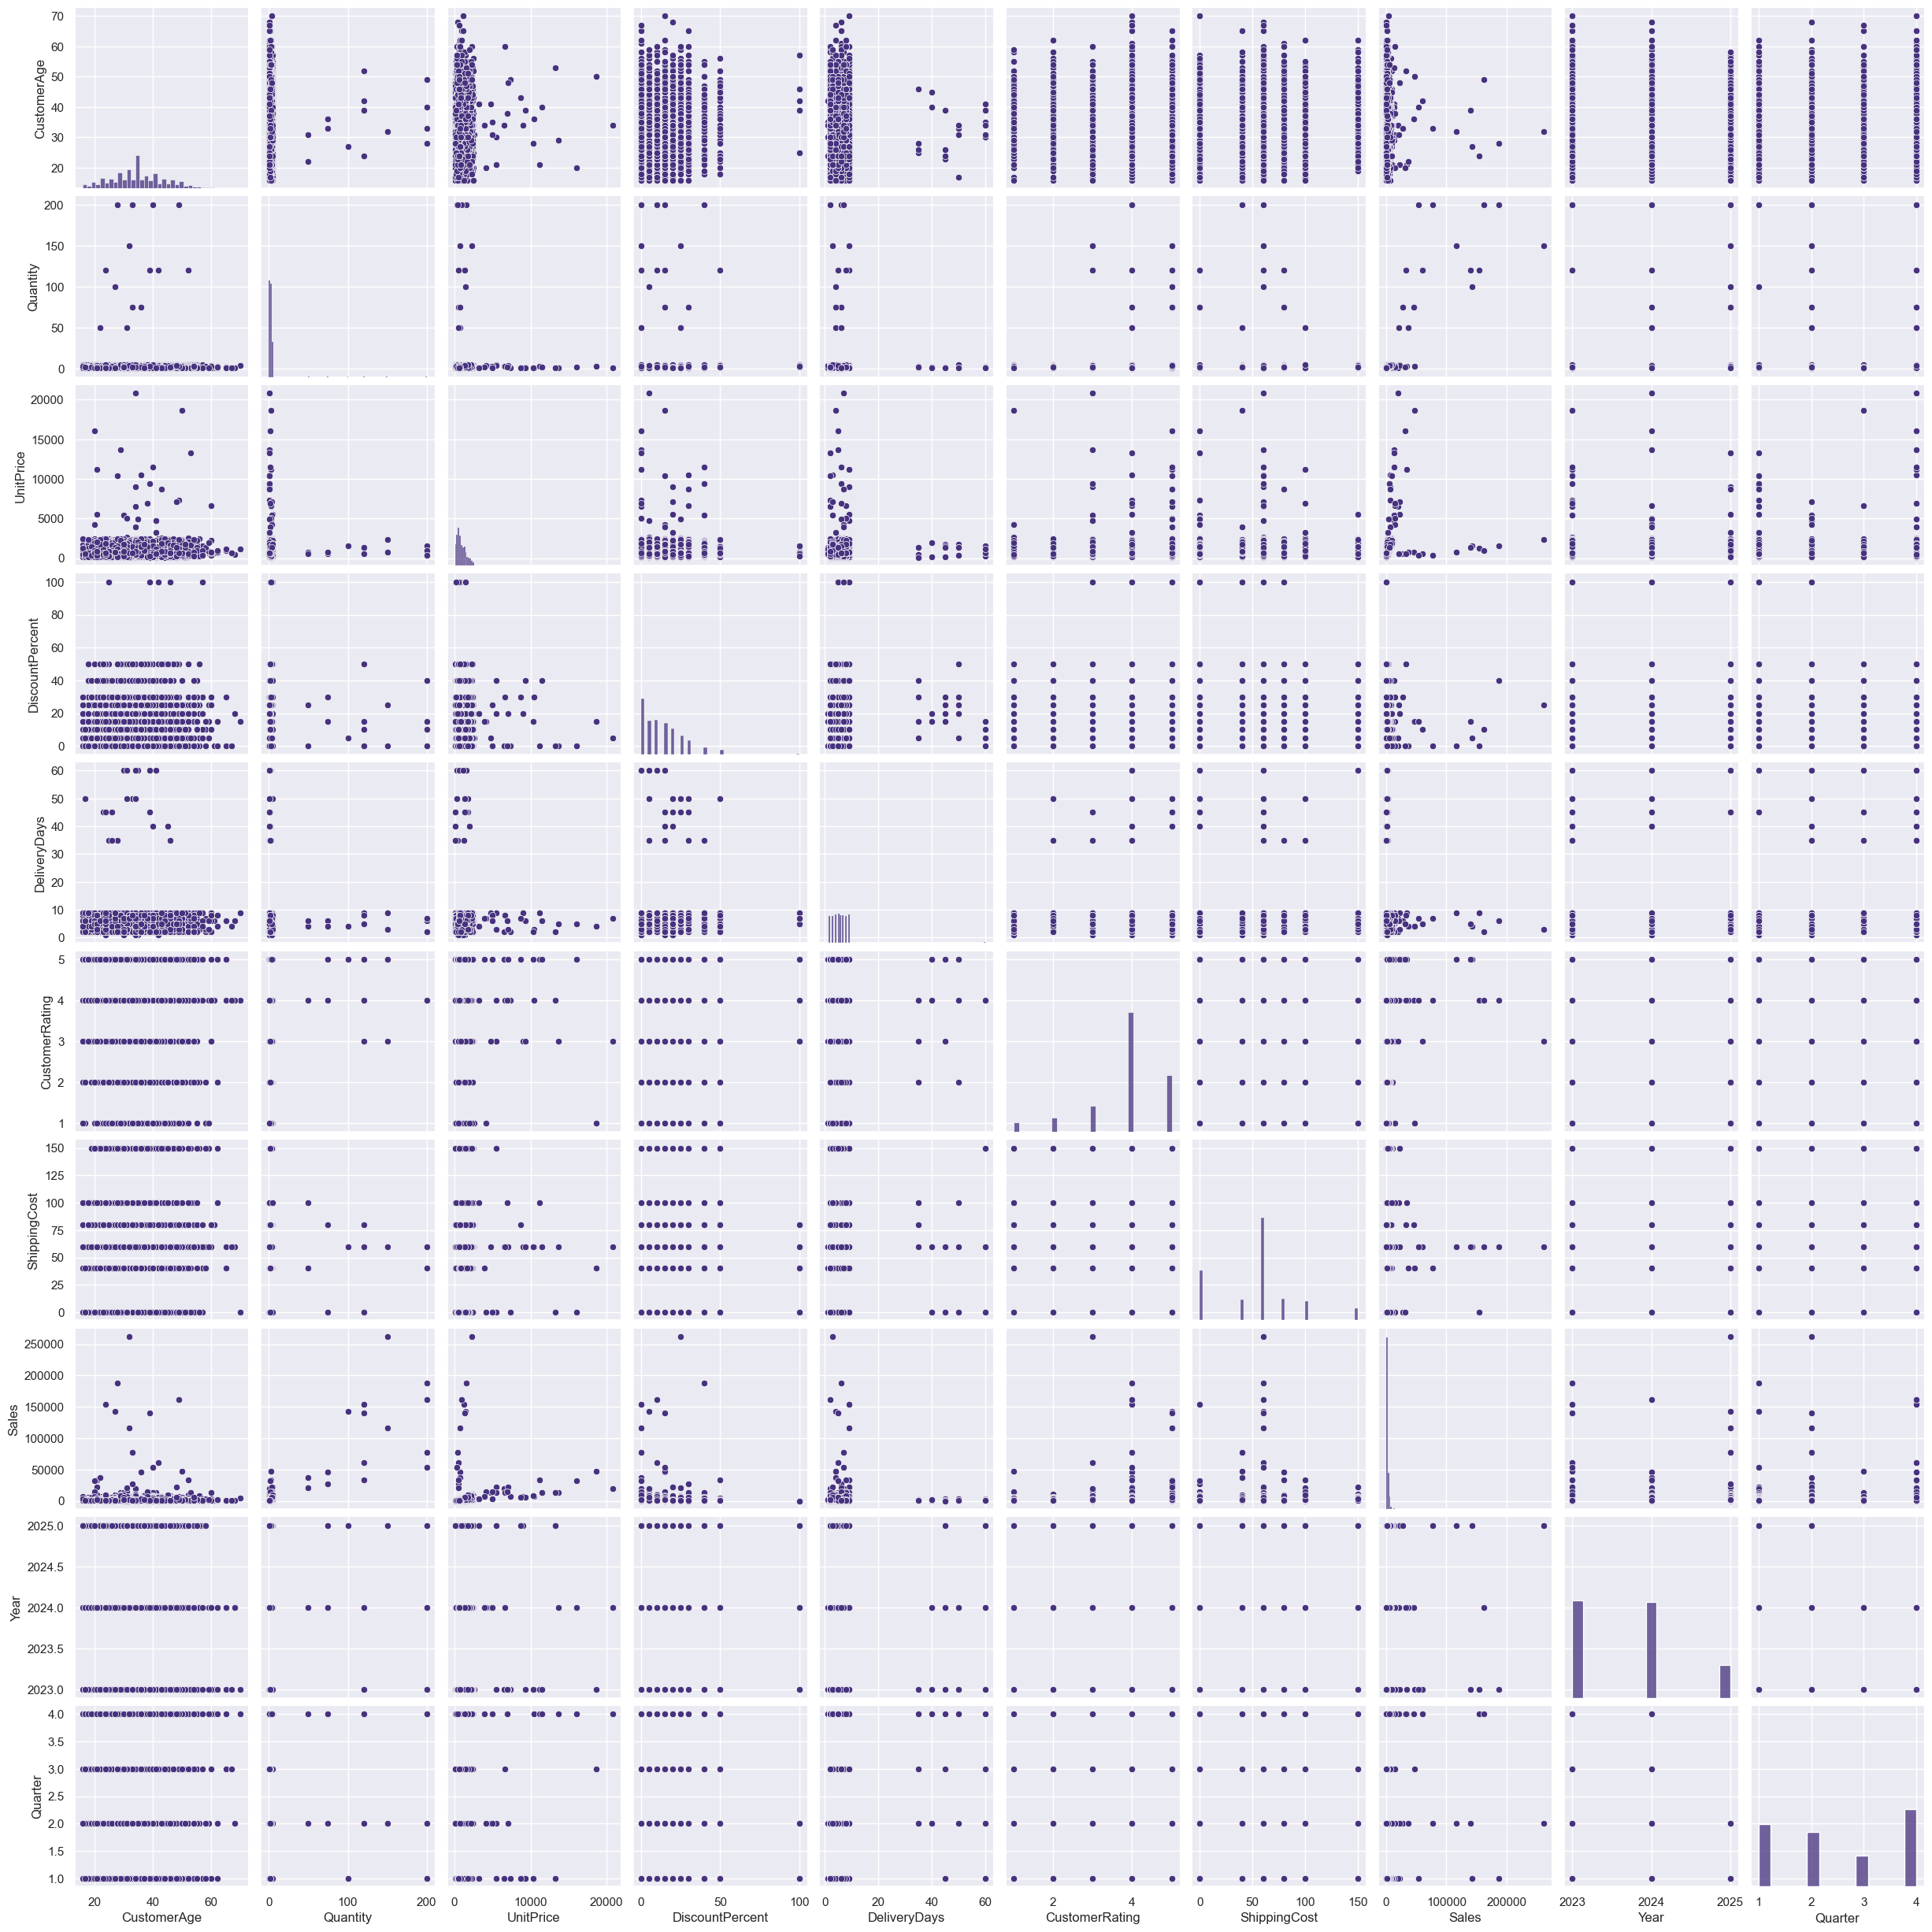

In [90]:
sns.pairplot(df)

- `PairPlot` shows almost all column are non related to each other except sales,unitprice and quqntity.

In [91]:
df.head(5)

,OrderID,OrderDate,CustomerName,CustomerAge,Gender,CustomerCity,ProductCategory,ProductName,Quantity,UnitPrice,...,PaymentMethod,CustomerRating,ShippingCost,CouponCode,ReturnReason,Sales,Year,Month,Day,Quarter
0,ORD100674,2024-07-20,Diya Verma,34.0,Male,Delhi,Beauty & Personal Care,Lip Balm Pack,4.0,144.70,...,Net Banking,4.0,0.0,NaN,NaN,578.8000,2024,July,Saturday,3
1,ORD102063,2024-10-17,Reyansh Sharma,31.0,Male,Kolkata,Footwear,Formal Leather Shoes,2.0,486.07,...,Debit Card,4.0,0.0,NEWUSER15,NaN,583.2840,2024,October,Thursday,4
2,ORD100377,2024-11-11,Sara Deshmukh,51.0,Male,Pune,Apparel,Men Cotton T-Shirt,1.0,852.46,...,Credit Card,4.0,60.0,FEST20,NaN,827.2140,2024,November,Monday,4
3,ORD100802,2024-04-14,Riya Kapoor,49.0,Male,Nagpur,Apparel,Men Cotton T-Shirt,1.0,1246.09,...,UPI,4.0,60.0,NEWUSER15,NaN,1306.0900,2024,April,Sunday,2
4,ORD101208,2023-09-17,Sneha Pillai,39.0,Male,Lucknow,Grocery,Green Tea Pack,1.0,379.31,...,Debit Card,4.0,80.0,FLAT100,NaN,364.4825,2023,September,Sunday,3


<BarContainer object of 6 artists>

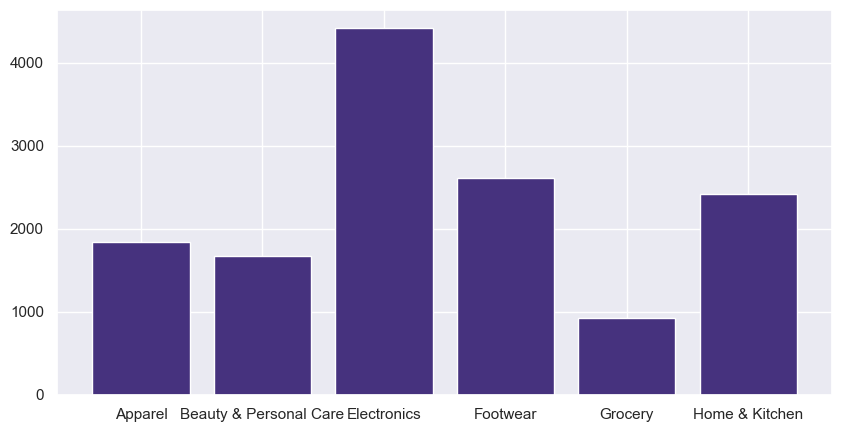

In [92]:
top_category = df.groupby('ProductCategory')['Sales'].mean()
plt.figure(figsize = (10,5))
plt.bar(top_category.index ,top_category.values)

In [93]:
cols = ['Gender','CustomerCity','PaymentMethod','Year','Month','Day','Quarter']

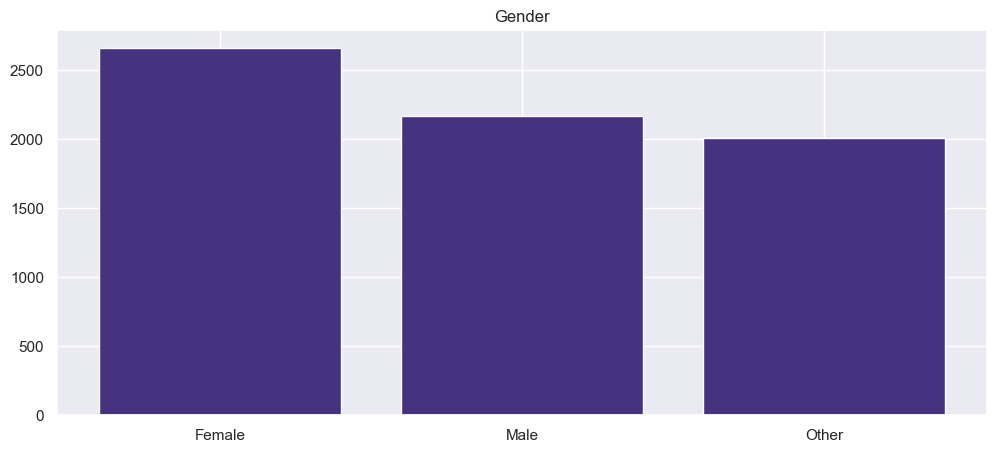

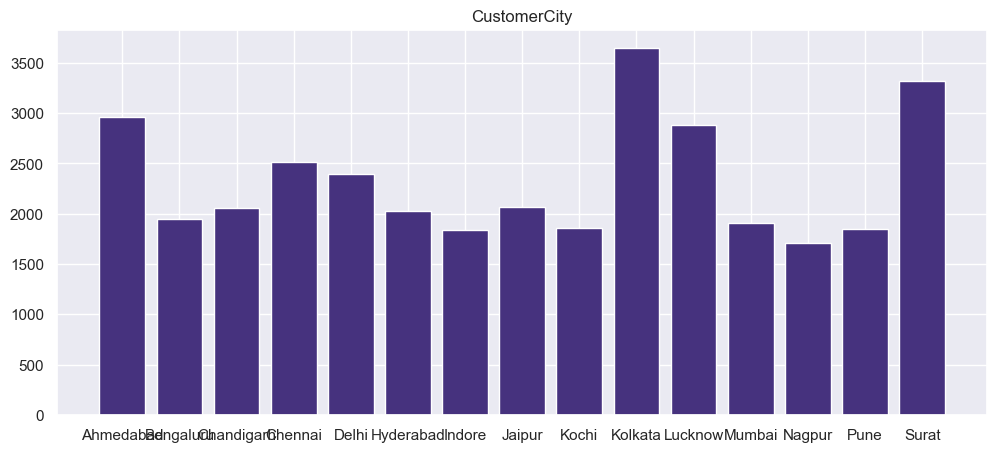

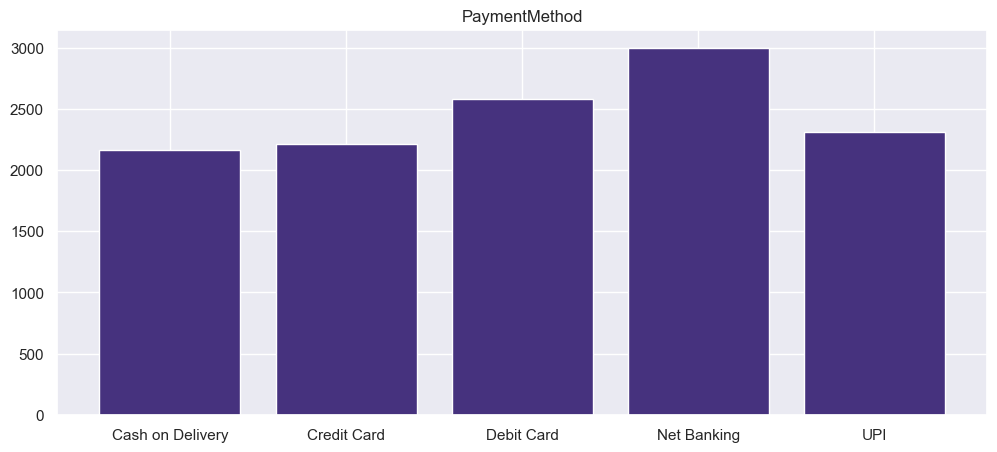

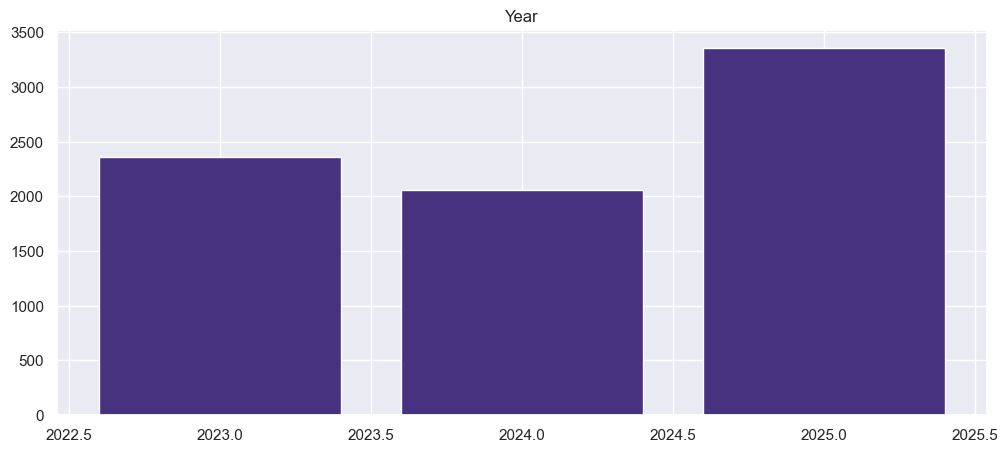

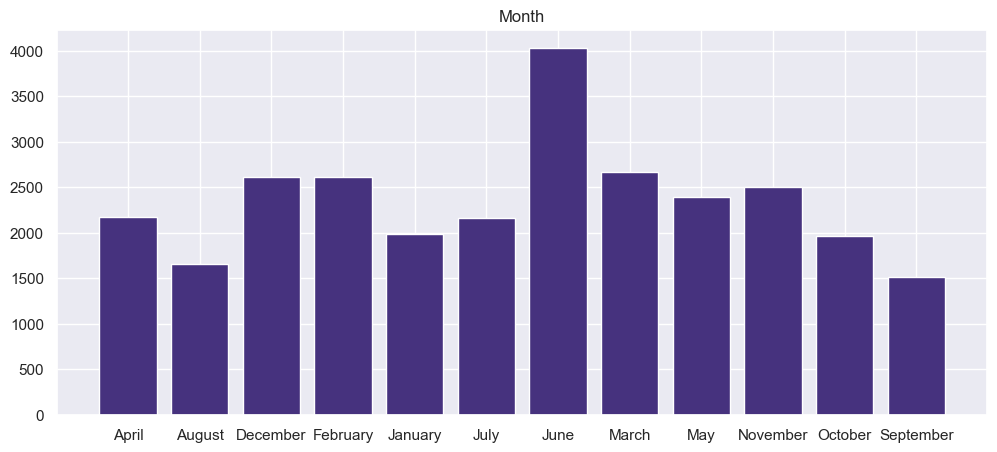

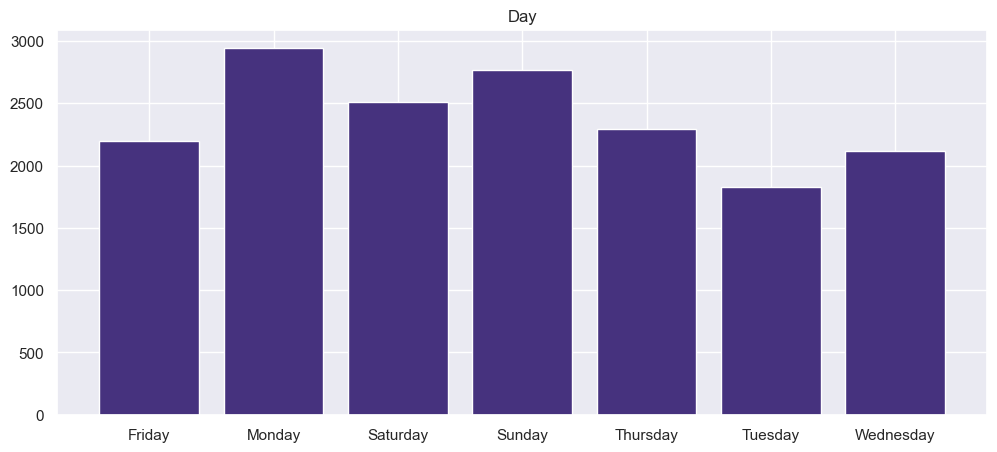

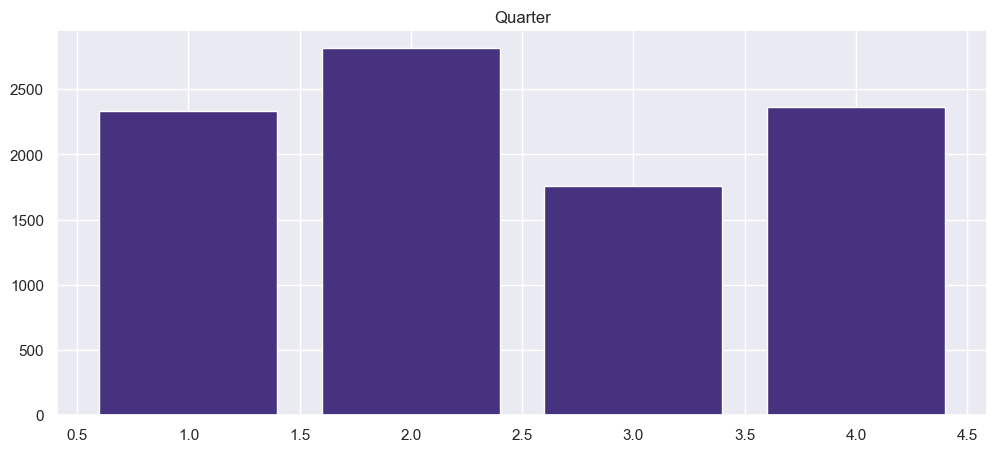

In [94]:
for i in cols:
    top_category = df.groupby(i)['Sales'].mean()
    plt.figure(figsize = (12,5))
    plt.bar(top_category.index ,top_category.values)
    plt.title(i)
    plt.show()

<Axes: xlabel='ProductCategory', ylabel='count'>

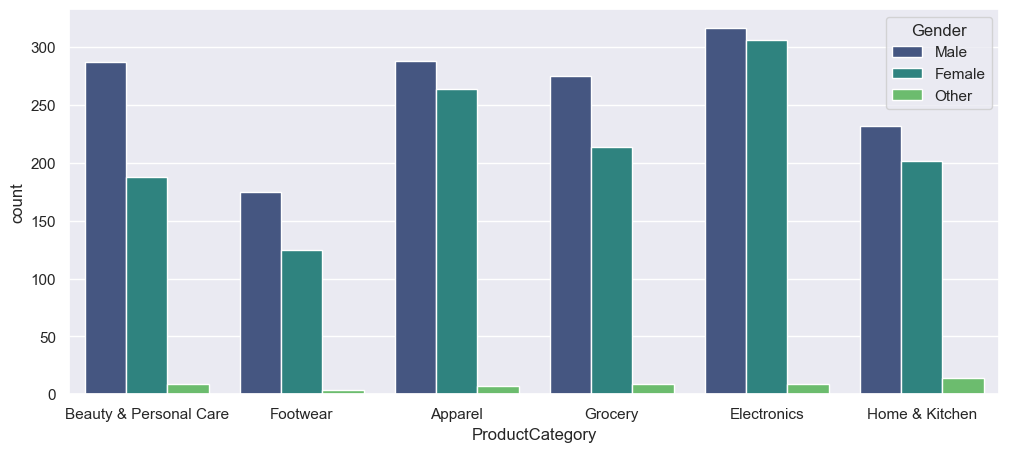

In [95]:
plt.figure(figsize = (12,5))
sns.countplot( x = df['ProductCategory'],hue = df['Gender'],palette = 'viridis')

In [96]:
df.columns

Index(['OrderID', 'OrderDate', 'CustomerName', 'CustomerAge', 'Gender',
       'CustomerCity', 'ProductCategory', 'ProductName', 'Quantity',
       'UnitPrice', 'DiscountPercent', 'DeliveryDays', 'PaymentMethod',
       'CustomerRating', 'ShippingCost', 'CouponCode', 'ReturnReason', 'Sales',
       'Year', 'Month', 'Day', 'Quarter'],
      dtype='object')

<Axes: xlabel='Gender', ylabel='count'>

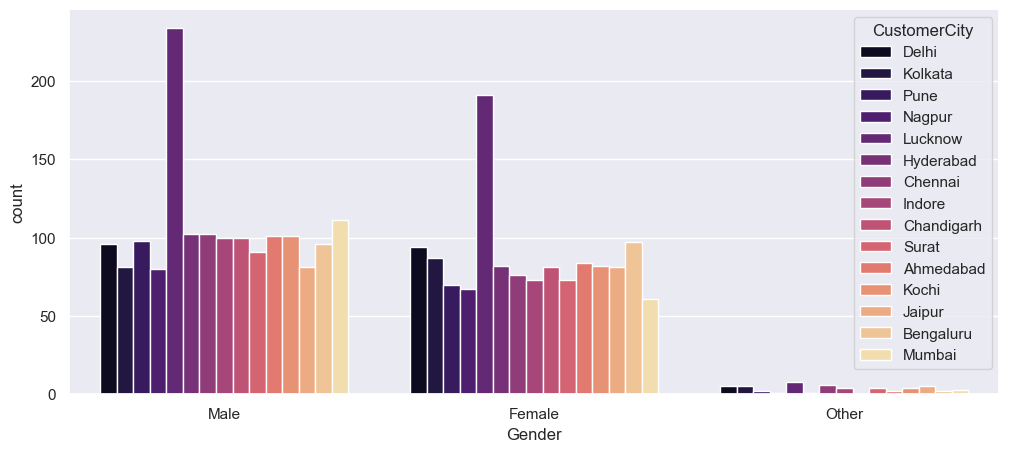

In [97]:
plt.figure(figsize = (12,5))
sns.countplot(x = df['Gender'],hue = df['CustomerCity'],palette = 'magma')

# Outlier
- Outlier is defined as number is far away from the mejority of the number

<Axes: xlabel='CustomerAge'>

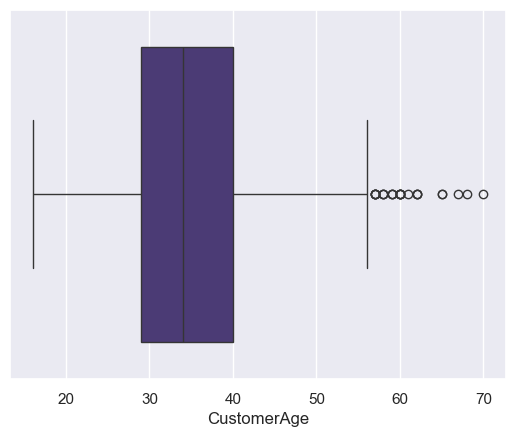

In [98]:
sns.boxplot(x = df['CustomerAge'])

<Axes: >

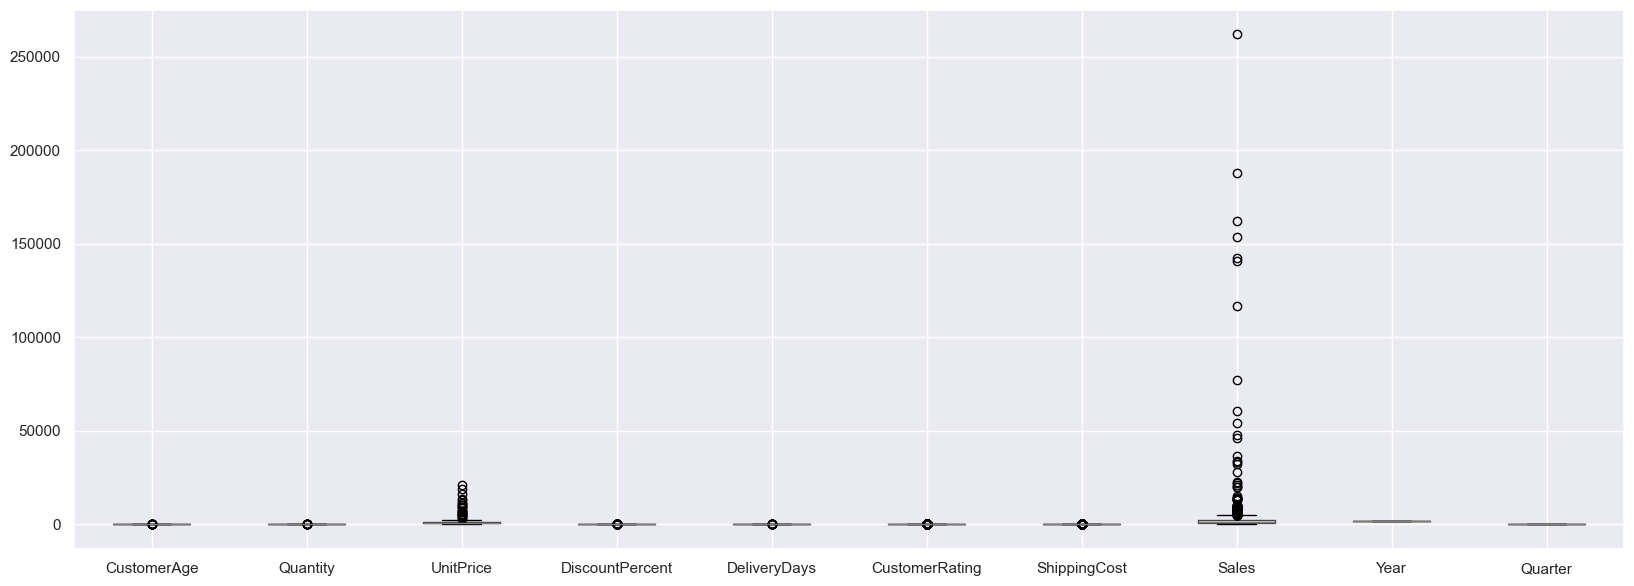

In [99]:
plt.figure(figsize = (20,7),dpi = 100)
df.boxplot()

# Deal with Outlier

In [100]:
df.describe()

,OrderDate,CustomerAge,Quantity,UnitPrice,DiscountPercent,DeliveryDays,CustomerRating,ShippingCost,Sales,Year,Quarter
count,2925,2925.000000,2925.000000,2925.000000,2925.000000,2925.000000,2925.00000,2925.000000,2925.000000,2925.000000,2925.000000
mean,2024-03-20 20:16:59.076922880,34.609573,2.748376,997.884354,12.994872,5.837265,3.88000,54.902564,2380.787576,2023.715897,2.545299
min,2023-01-01 00:00:00,16.000000,0.000000,80.350000,0.000000,1.000000,1.00000,0.000000,0.000000,2023.000000,1.000000
25%,2023-09-22 00:00:00,29.000000,1.000000,478.610000,5.000000,4.000000,4.00000,40.000000,661.848000,2023.000000,1.000000
50%,2024-02-14 00:00:00,34.000000,2.000000,786.670000,10.000000,5.000000,4.00000,60.000000,1253.740000,2024.000000,2.000000
75%,2024-11-06 00:00:00,40.000000,3.000000,1328.540000,20.000000,8.000000,5.00000,60.000000,2338.550000,2024.000000,4.000000
max,2025-06-29 00:00:00,70.000000,200.000000,20819.867889,100.000000,60.000000,5.00000,150.000000,261862.125000,2025.000000,4.000000
std,NaN,8.952300,9.853663,1030.098789,12.356771,4.552346,0.99432,37.602106,8937.941312,0.704905,1.220163


<Axes: xlabel='CustomerAge'>

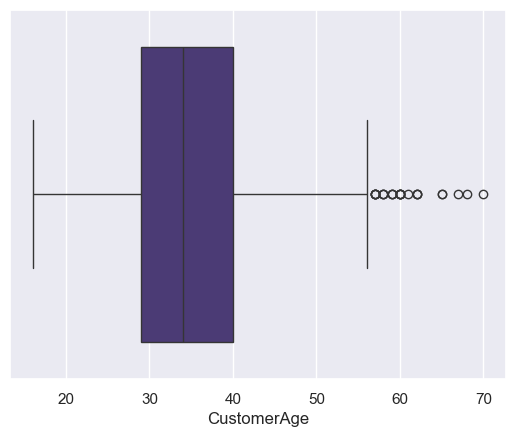

In [101]:
sns.boxplot(x = df['CustomerAge'])

In [102]:
#functiom know before capping.
x = np.array([1,2,20,25,26,30,28,300,400])
x

array([  1,   2,  20,  25,  26,  30,  28, 300, 400])

In [103]:
x = np.clip(x,20,30)

In [104]:
x

array([20, 20, 20, 25, 26, 30, 28, 30, 30])

In [105]:
df['CustomerAge'].quantile(0.25)   #used to find percentile value of any column 0.75 means 75 percentile.

np.float64(29.0)

In [106]:
num_cols = df.select_dtypes([int,float]).columns
num_cols

Index(['CustomerAge', 'Quantity', 'UnitPrice', 'DiscountPercent',
       'DeliveryDays', 'CustomerRating', 'ShippingCost', 'Sales', 'Year',
       'Quarter'],
      dtype='object')

In [107]:
for i in num_cols:
    q1 = df[i].quantile(0.25)
    q3 = df[i].quantile(0.75)
    iqr = q3-q1
    lower = q1 - (1.5*iqr)
    upper = q3 + (1.5*iqr)
    df[i] = np.clip(df[i],lower,upper)    

<Axes: >

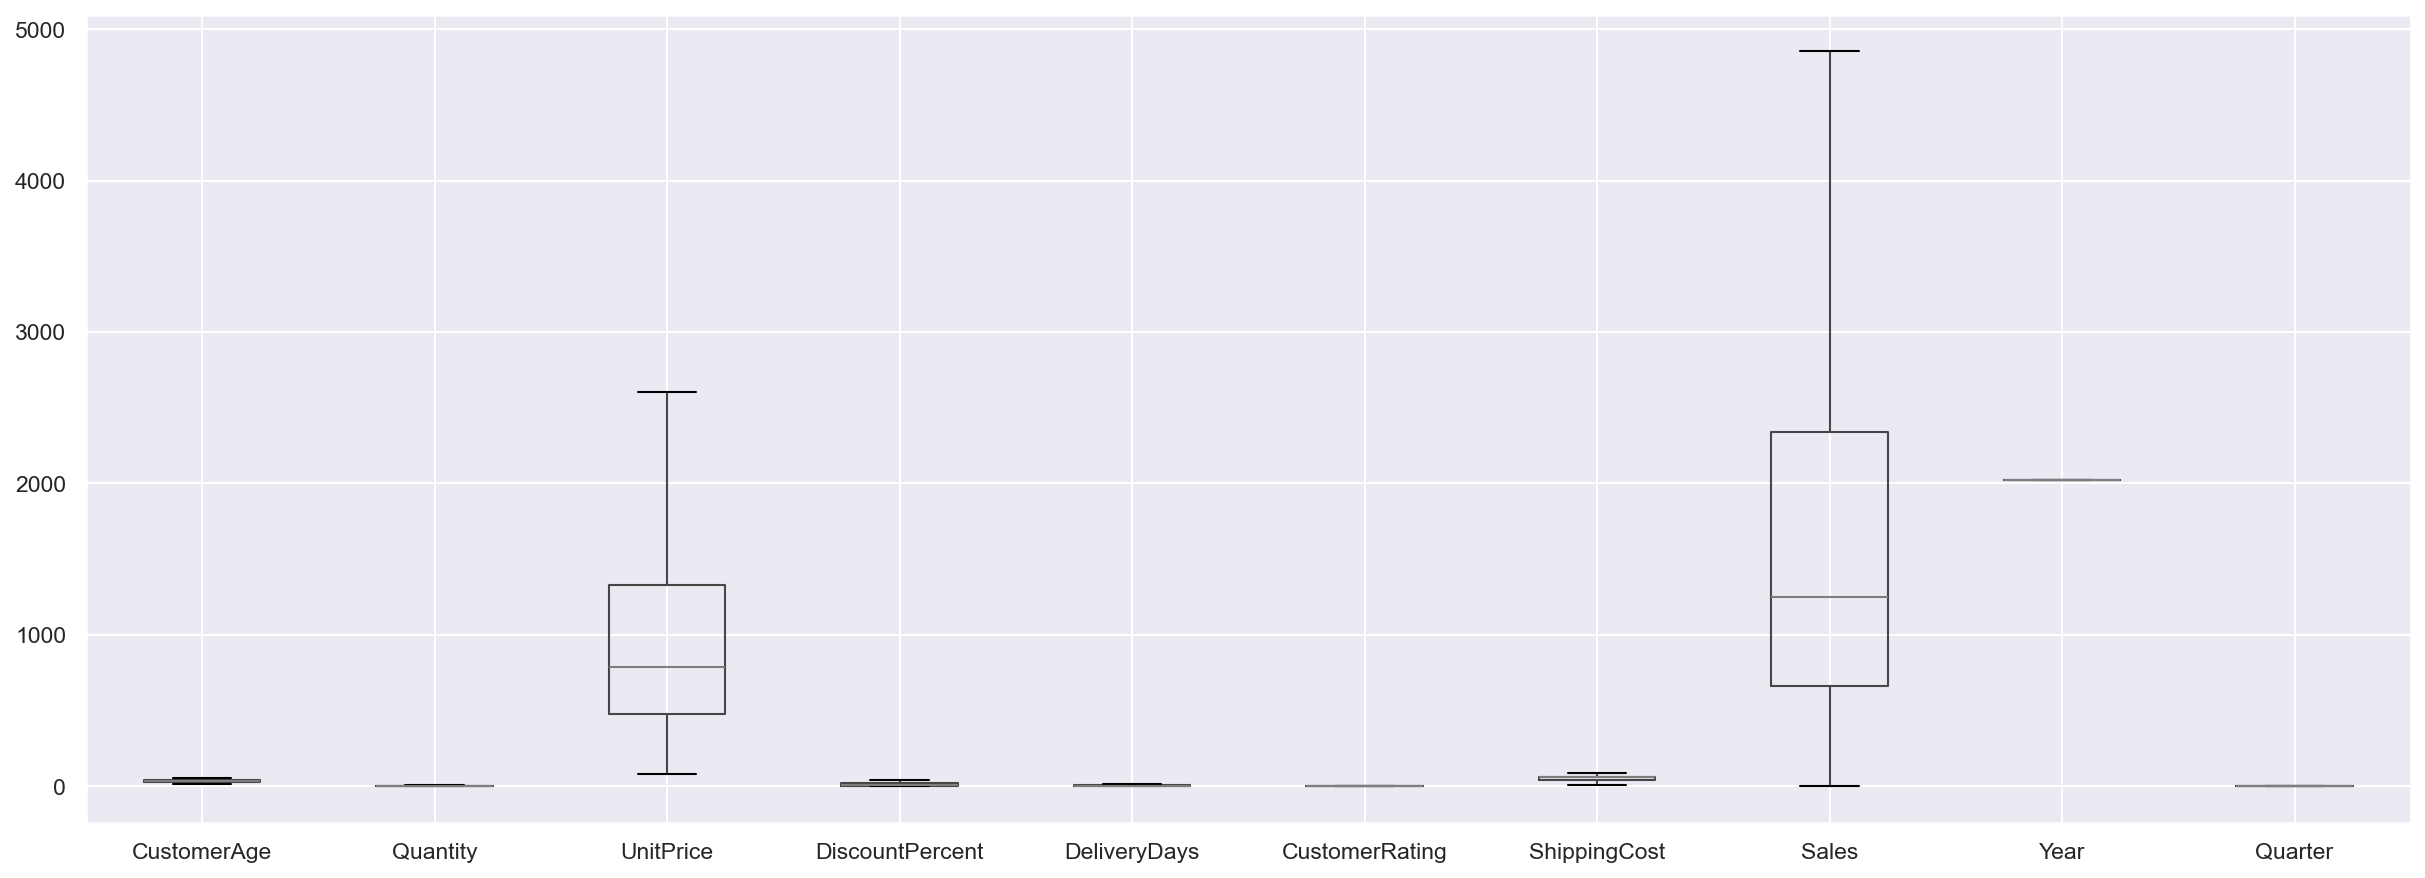

In [108]:
plt.figure(figsize = (20,7),dpi = 150)
df.boxplot()

In [109]:
df.shape

(2925, 22)

# Saving cleaned dataset for further use.

In [110]:
df.to_csv('cleaned_data.csv')